# Discord Sentiment Bot – RNN, LSTM i GRU

Trenujemy trzy sieci rekurencyjne do analizy sentymentu, porównujemy je i uruchamiamy bota Discord, który z nich korzysta.

## 1. Biblioteki

In [26]:
import asyncio
import json
import os
import time
from collections import Counter
from typing import Literal

import discord
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from discord import app_commands
from dotenv import load_dotenv
from nltk.tokenize import TweetTokenizer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score, recall_score
from torch import nn

load_dotenv()
torch.manual_seed(42)
RETRAIN = False  # True = trenuj modele od nowa zamiast wczytywać z folderu models/
os.makedirs("models", exist_ok=True)
os.makedirs("report", exist_ok=True)

## 2. Dane

Zbiór **TweetEval – sentiment**: angielskie tweety z klasami negatywny (0), neutralny (1) i pozytywny (2). Ma gotowy podział na train, validation i test.

In [27]:
data = load_dataset("cardiffnlp/tweet_eval", "sentiment")
LABELS = ["negatywny", "neutralny", "pozytywny"]

for split in ["train", "validation", "test"]:
    print(split, len(data[split]), Counter(data[split]["label"]))

train 45615 Counter({1: 20673, 2: 17849, 0: 7093})
validation 2000 Counter({1: 869, 2: 819, 0: 312})
test 12284 Counter({1: 5937, 0: 3972, 2: 2375})


## 3. Tokenizacja i kodowanie

`TweetTokenizer` zostawia emotikony jako osobne tokeny. Każde słowo zamieniamy na numer ze słownika, a każdy tekst na listę 40 liczb.

In [28]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)
MAX_LEN = 40

if RETRAIN or not os.path.exists("models/vocab.json"):
    counts = Counter()
    for text in data["train"]["text"]:
        counts.update(tokenizer.tokenize(text))
    vocab = {"<pad>": 0, "<unk>": 1}
    for word, count in counts.most_common(20000):
        if count >= 2:
            vocab[word] = len(vocab)
    json.dump(vocab, open("models/vocab.json", "w"))
else:
    vocab = json.load(open("models/vocab.json"))


def encode(text):
    ids = [vocab.get(word, 1) for word in tokenizer.tokenize(text)][:MAX_LEN]
    return [0] * (MAX_LEN - len(ids)) + ids  # zera z lewej strony


X_train = torch.tensor([encode(text) for text in data["train"]["text"]])
X_val = torch.tensor([encode(text) for text in data["validation"]["text"]])
X_test = torch.tensor([encode(text) for text in data["test"]["text"]])
y_train = torch.tensor(data["train"]["label"])
y_val = torch.tensor(data["validation"]["label"])
y_test = torch.tensor(data["test"]["label"])

print("Słownik:", len(vocab))
print(tokenizer.tokenize("Soooo happy :) @user"), encode("Soooo happy :) @user")[-3:])

Słownik: 20002
['sooo', 'happy', ':)'] [1344, 133, 142]


## 4. Modele

Wszystkie modele mają tę samą budowę: Embedding → RNN / LSTM / GRU → warstwa liniowa z 3 wyjściami.

In [29]:
class SentimentNet(nn.Module):
    def __init__(self, cell):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), 100, padding_idx=0)
        if cell == "rnn":
            self.rnn = nn.RNN(100, 128, batch_first=True)
        elif cell == "lstm":
            self.rnn = nn.LSTM(100, 128, batch_first=True)
        else:
            self.rnn = nn.GRU(100, 128, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 3)

    def forward(self, x):
        _, h = self.rnn(self.embedding(x))
        if isinstance(h, tuple):  # LSTM zwraca (h, c)
            h = h[0]
        return self.fc(self.dropout(h[-1]))


names = ["rnn", "lstm", "gru"]

## 5. Trening

8 epok, Adam, batch 64. Rzadsza klasa (negatywna) dostaje większą wagę w funkcji straty. Zapisujemy wagi z epoki o najlepszym F1 na walidacji.

In [30]:
def train_model(name):
    torch.manual_seed(42)
    model = SentimentNet(name)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    weights = len(y_train) / (3 * torch.bincount(y_train).float())
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    best_f1 = 0

    for epoch in range(8):
        model.train()
        order = torch.randperm(len(X_train))
        for i in range(0, len(X_train), 64):
            batch = order[i:i + 64]
            optimizer.zero_grad()
            loss = loss_fn(model(X_train[batch]), y_train[batch])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_f1 = f1_score(y_val, model(X_val).argmax(1), average="macro")
        print(name, "epoka", epoch + 1, "F1 walidacja:", round(val_f1, 3))
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), f"models/{name}.pt")

In [31]:
if RETRAIN or not os.path.exists("models/train_times.json"):
    train_times = {}
    for name in names:
        start = time.time()
        train_model(name)
        train_times[name] = time.time() - start
    json.dump(train_times, open("models/train_times.json", "w"))
else:
    train_times = json.load(open("models/train_times.json"))
    print("Wczytano zapisane modele")

models = {}
for name in names:
    models[name] = SentimentNet(name)
    models[name].load_state_dict(torch.load(f"models/{name}.pt"))
    models[name].eval()

Wczytano zapisane modele


## 6. Wyniki na zbiorze testowym

Wszystkie modele sprawdzamy na tym samym zbiorze testowym. Czas predykcji to średnia dla jednej wiadomości.

In [32]:
def predict(text, name):
    with torch.no_grad():
        probs = torch.softmax(models[name](torch.tensor([encode(text)])), dim=1)[0]
    label = int(probs.argmax())
    return label, float(probs[label])


test_texts = data["test"]["text"]
y_true = y_test.numpy()
probs = {}
preds = {}
with torch.no_grad():
    for name in names:
        probs[name] = torch.softmax(models[name](X_test), dim=1).numpy()
        preds[name] = probs[name].argmax(1)

rows = []
for name in names:
    start = time.time()
    for text in test_texts[:500]:
        predict(text, name)
    predict_ms = (time.time() - start) / 500 * 1000
    rows.append([name.upper(),
                 accuracy_score(y_true, preds[name]),
                 precision_score(y_true, preds[name], average="macro"),
                 recall_score(y_true, preds[name], average="macro"),
                 f1_score(y_true, preds[name], average="macro"),
                 train_times[name],
                 predict_ms])

results = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "f1", "trening [s]", "predykcja [ms]"])
results = results.set_index("model").round(3)
results

,accuracy,precision,recall,f1,trening [s],predykcja [ms]
model,,,,,,
RNN,0.556,0.546,0.565,0.551,31.595,0.224
LSTM,0.585,0.577,0.579,0.577,95.655,0.408
GRU,0.577,0.565,0.582,0.571,80.077,0.398


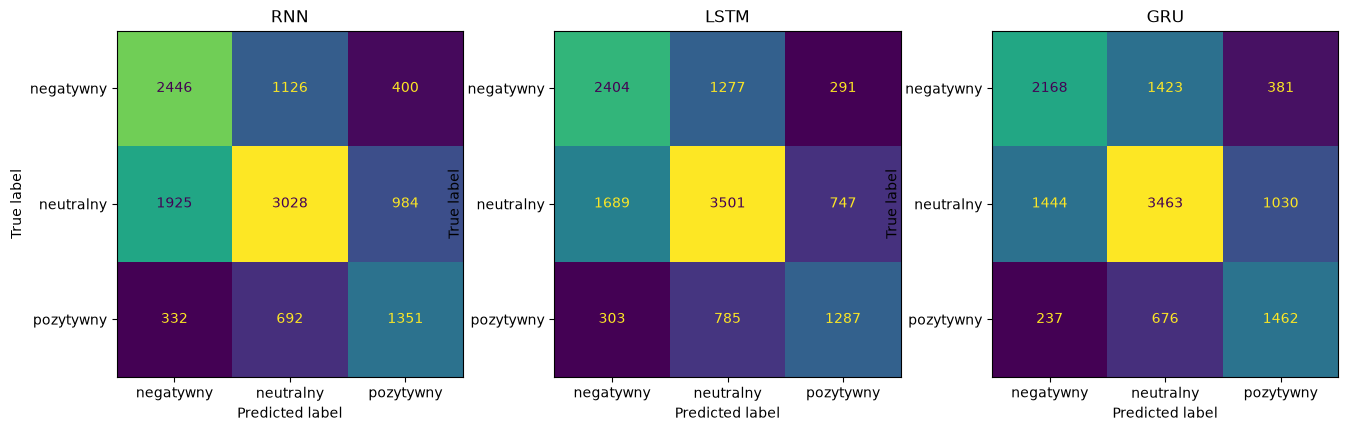

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, name in enumerate(names):
    ConfusionMatrixDisplay.from_predictions(y_true, preds[name], display_labels=LABELS, ax=axes[i], colorbar=False)
    axes[i].set_title(name.upper())
plt.savefig("report/confusion_matrices.png")
plt.show()

## 7. Eksperymenty

Dzielimy test na grupy: krótkie i długie wiadomości, z negacją, z emotikonami i ze slangiem. Dla każdej grupy liczymy F1 modeli i to, jak często wszystkie trzy modele się zgadzają.

In [34]:
tokens = [tokenizer.tokenize(text) for text in test_texts]
lengths = np.array([len(t) for t in tokens])
negations = ["not", "no", "never", "nothing", "nobody", "dont", "cant", "wont"]
emoticons = [":)", ":(", ":d", ":p", ";)", "<3", ":/", "😂", "😍", "❤", "😭", "😊", "🙏", "👍", "😩", "😡"]
slang = ["lol", "lmao", "omg", "wtf", "idk", "tbh", "smh", "u", "ur", "gonna", "wanna", "bruh", "af", "pls"]

groups = {
    "cały test": lengths >= 0,
    "krótkie (≤10 tokenów)": lengths <= 10,
    "długie (≥25 tokenów)": lengths >= 25,
    "z negacją": np.array([any(w in negations or w.endswith("n't") for w in t) for t in tokens]),
    "z emotikonami": np.array([any(w in emoticons for w in t) for t in tokens]),
    "ze slangiem": np.array([any(w in slang for w in t) for t in tokens]),
}
all_agree = (preds["rnn"] == preds["lstm"]) & (preds["lstm"] == preds["gru"])

rows = []
for group, mask in groups.items():
    row = [group, mask.sum()]
    for name in names:
        row.append(f1_score(y_true[mask], preds[name][mask], average="macro"))
    row.append(all_agree[mask].mean())
    rows.append(row)
pd.DataFrame(rows, columns=["grupa", "liczba", "RNN", "LSTM", "GRU", "zgodność modeli"]).round(3)

,grupa,liczba,RNN,LSTM,GRU,zgodność modeli
0,cały test,12284,0.551,0.577,0.571,0.602
1,krótkie (≤10 tokenów),2456,0.540,0.571,0.569,0.631
2,długie (≥25 tokenów),1514,0.517,0.548,0.569,0.567
3,z negacją,2172,0.470,0.492,0.501,0.613
4,z emotikonami,587,0.501,0.533,0.553,0.566
5,ze slangiem,454,0.550,0.559,0.566,0.593


Kiedy modele są zgodne, a kiedy nie:

In [35]:
print("Wszystkie 3 modele zgodne:", round(all_agree.mean() * 100, 1), "%")
print("Accuracy, gdy są zgodne:", round((preds["lstm"] == y_true)[all_agree].mean(), 3))
for name in names:
    print(f"Accuracy {name.upper()}, gdy się różnią:", round((preds[name] == y_true)[~all_agree].mean(), 3))

print("\nPrzykłady różnic (prawdziwa | RNN, LSTM, GRU | tekst):")
for i in np.where(~all_agree)[0][:5]:
    print(LABELS[y_true[i]], "|", LABELS[preds["rnn"][i]], LABELS[preds["lstm"][i]], LABELS[preds["gru"][i]], "|", test_texts[i])

Wszystkie 3 modele zgodne: 60.2 %
Accuracy, gdy są zgodne: 0.659
Accuracy RNN, gdy się różnią: 0.4
Accuracy LSTM, gdy się różnią: 0.475
Accuracy GRU, gdy się różnią: 0.455

Przykłady różnic (prawdziwa | RNN, LSTM, GRU | tekst):
neutralny | neutralny pozytywny neutralny | OH: “I had a blue penis while I was this” [playing with Google Earth VR]
neutralny | negatywny neutralny neutralny | @user @user That's coming, but I think the victims are going to be Medicaid recipients.
pozytywny | pozytywny pozytywny neutralny | I think I may be finally in with the in crowd #mannequinchallenge  #grads2014 @user
neutralny | negatywny neutralny negatywny | Savchenko now Saakashvili took drug test live on Ukraine TV. To prove they are not drug-fueled loonies?
pozytywny | negatywny neutralny neutralny | Twitter's #ThankYouObama Shows Heartfelt Gratitude To POTUS


Własne przykłady z negacją, emotikonami i slangiem:

In [36]:
my_examples = [
    "I love this phone",
    "I don't love this phone",
    "This is not bad at all",
    "This is not good",
    "Best day ever :)",
    "Great, another Monday :(",
    "omg yesss 😍😍",
    "ugh this sucks smh",
    "lol that party was lit",
    "The meeting is moved to 5pm on Friday",
    "ok",
]

for text in my_examples:
    answer = []
    for name in names:
        label, conf = predict(text, name)
        answer.append(f"{name.upper()}: {LABELS[label]} ({conf:.0%})")
    print(text, "->", ", ".join(answer))

I love this phone -> RNN: pozytywny (86%), LSTM: pozytywny (88%), GRU: pozytywny (96%)
I don't love this phone -> RNN: pozytywny (75%), LSTM: pozytywny (74%), GRU: pozytywny (91%)
This is not bad at all -> RNN: negatywny (75%), LSTM: negatywny (92%), GRU: negatywny (80%)
This is not good -> RNN: negatywny (70%), LSTM: negatywny (79%), GRU: negatywny (89%)
Best day ever :) -> RNN: pozytywny (98%), LSTM: pozytywny (98%), GRU: pozytywny (99%)
Great, another Monday :( -> RNN: negatywny (68%), LSTM: negatywny (71%), GRU: negatywny (63%)
omg yesss 😍😍 -> RNN: pozytywny (76%), LSTM: pozytywny (54%), GRU: pozytywny (83%)
ugh this sucks smh -> RNN: negatywny (98%), LSTM: negatywny (98%), GRU: negatywny (100%)
lol that party was lit -> RNN: pozytywny (59%), LSTM: pozytywny (65%), GRU: pozytywny (70%)
The meeting is moved to 5pm on Friday -> RNN: neutralny (55%), LSTM: neutralny (77%), GRU: neutralny (77%)
ok -> RNN: neutralny (65%), LSTM: pozytywny (55%), GRU: neutralny (49%)


Przykłady poprawnych i błędnych klasyfikacji najlepszego modelu:

In [37]:
best = results["f1"].idxmax().lower()
conf = probs[best].max(1)
correct = np.where(preds[best] == y_true)[0]
wrong = np.where(preds[best] != y_true)[0]
wrong = wrong[np.argsort(-conf[wrong])]  # najpierw błędy z największą pewnością

print("Najlepszy model:", best.upper())
print("\nPoprawne:")
for i in correct[:5]:
    print(f"{LABELS[y_true[i]]} ({conf[i]:.0%}) | {test_texts[i]}")
print("\nBłędne (prawdziwa -> przewidziana):")
for i in wrong[:5]:
    print(f"{LABELS[y_true[i]]} -> {LABELS[preds[best][i]]} ({conf[i]:.0%}) | {test_texts[i]}")

Najlepszy model: LSTM

Poprawne:
neutralny (44%) | @user @user That's coming, but I think the victims are going to be Medicaid recipients.
pozytywny (73%) | I think I may be finally in with the in crowd #mannequinchallenge  #grads2014 @user
neutralny (52%) | Savchenko now Saakashvili took drug test live on Ukraine TV. To prove they are not drug-fueled loonies?
neutralny (50%) | How many more days until opening day? 😩
neutralny (41%) | All CSG and Fracking all around Australia is to cease and Mining Entities held Accountable! - Sign the Petition!

Błędne (prawdziwa -> przewidziana):
neutralny -> pozytywny (99%) | Love is love. No room for hate! @user from @user  -  @user @user  para Cuando Un...
neutralny -> pozytywny (99%) | Oh Happy Day, Conservatives Laugh As LiberalsCry And All Their Dreams Fade Away @user
neutralny -> pozytywny (99%) | @user @user @user -you openly support #Hamas & #Hezbollah - good luck w/the 72 virgin boys u get in 'paradise' 🖕from🇺🇸
neutralny -> pozytywny (99%) 

### Wnioski

- **Najlepszy jest LSTM** (F1 0.577), GRU jest prawie tak samo dobry (0.571), a RNN najsłabszy (0.551). Wszystkie najczęściej mylą klasę neutralną z negatywną.
- **Czas:** RNN trenuje się około 3 razy szybciej (32 s, LSTM 96 s, GRU 80 s) i przewiduje około 2 razy szybciej. W bocie różnicy nie widać, bo każda predykcja trwa poniżej 1 ms.
- **Długie wiadomości:** RNN i LSTM tracą najwięcej, GRU trzyma poziom.
- **Negacje** to najtrudniejsza grupa (F1 około 0.47–0.50). „I don't love this phone” i „not bad at all” wszystkie modele oceniają źle, bo patrzą głównie na pojedyncze słowa.
- **Emotikony i slang:** proste przykłady (`:)`, `:(`, 😍, *lol*, *smh*) są rozpoznawane, ale grupa z emotikonami w teście jest trudniejsza niż cały zbiór.
- **Zgodność:** wszystkie trzy modele zgadzają się w 60% wiadomości i wtedy mają rację w 66% przypadków. Gdy się różnią, trafiają tylko w 40–48% przypadków. Częściej różnią się przy długich wiadomościach i tych z emotikonami.

## 8. Bot Discord

Bot reaguje tylko na komendy, więc nie czyta innych wiadomości i nic nie zapisuje. Modele są już w pamięci, więc `/model` tylko zmienia aktywny model. Najpierw sprawdzamy odpowiedzi bez Discorda.

In [38]:
current_model = best
stats = Counter()


def sentiment_reply(text, name):
    label, conf = predict(text, name)
    return f"**{name.upper()}**: {LABELS[label]} (pewność {conf:.1%})"


def compare_reply(text):
    answer = f"„{text}”\n"
    labels = []
    for name in names:
        answer += sentiment_reply(text, name) + "\n"
        labels.append(predict(text, name)[0])
    if len(set(labels)) == 1:
        answer += "Wszystkie modele są zgodne."
    else:
        answer += "Modele się różnią."
    return answer


def stats_reply():
    answer = f"Aktywny model: **{current_model.upper()}**\n\nWyniki na zbiorze testowym:\n"
    for name in names:
        r = results.loc[name.upper()]
        answer += f"{name.upper()}: accuracy {r['accuracy']}, F1 {r['f1']}, trening {r['trening [s]']:.0f} s\n"
    answer += f"\nUżycie komend: {dict(stats)}\nTreść wiadomości nie jest zapisywana."
    return answer


print(sentiment_reply("I love this phone :)", current_model))
print(compare_reply("ok"))
print(stats_reply())

**LSTM**: pozytywny (pewność 97.2%)
„ok”
**RNN**: neutralny (pewność 64.6%)
**LSTM**: pozytywny (pewność 55.3%)
**GRU**: neutralny (pewność 49.0%)
Modele się różnią.
Aktywny model: **LSTM**

Wyniki na zbiorze testowym:
RNN: accuracy 0.556, F1 0.551, trening 32 s
LSTM: accuracy 0.585, F1 0.577, trening 96 s
GRU: accuracy 0.577, F1 0.571, trening 80 s

Użycie komend: {}
Treść wiadomości nie jest zapisywana.


Bot potrzebuje `DISCORD_TOKEN` i `DISCORD_GUILD_ID` w pliku `.env` (instrukcja w README).

In [39]:
client = discord.Client(intents=discord.Intents.default())
tree = app_commands.CommandTree(client)


@tree.command(name="sentiment", description="Sentyment tekstu aktywnym modelem")
async def sentiment_command(interaction: discord.Interaction, tekst: str):
    stats["sentiment"] += 1
    await interaction.response.send_message(f"„{tekst}”\n" + sentiment_reply(tekst, current_model))


@tree.command(name="model", description="Zmiana aktywnego modelu")
async def model_command(interaction: discord.Interaction, nazwa: Literal["rnn", "lstm", "gru"]):
    global current_model
    stats["model"] += 1
    current_model = nazwa
    await interaction.response.send_message(f"Aktywny model: **{nazwa.upper()}**")


@tree.command(name="compare", description="Porównanie RNN, LSTM i GRU")
async def compare_command(interaction: discord.Interaction, tekst: str):
    stats["compare"] += 1
    await interaction.response.send_message(compare_reply(tekst))


@tree.command(name="stats", description="Wyniki modeli i statystyki bota")
async def stats_command(interaction: discord.Interaction):
    stats["stats"] += 1
    await interaction.response.send_message(stats_reply())


@client.event
async def on_ready():
    guild = discord.Object(id=int(os.environ["DISCORD_GUILD_ID"]))
    tree.copy_global_to(guild=guild)
    await tree.sync(guild=guild)
    print("Bot działa jako", client.user)

Start bota (działa w tle):

In [ ]:
bot = asyncio.get_running_loop().create_task(client.start(os.environ["DISCORD_TOKEN"]))

Bot działa jako Chatbot NLP#2370
Bot działa jako Chatbot NLP#2370
Bot działa jako Chatbot NLP#2370
Bot działa jako Chatbot NLP#2370


Zatrzymanie bota:

In [41]:
# await client.close()